# CF Triads
Plot the original image alongside its 3 generated diffusion counterfactuals, to eyeball how different the 3 seeds turn out.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
# ── CONFIG ────────────────────────────────────────────────────────────────────
BASE_DIR      = "/zhome/d0/a/221493/thesis"
DATA_DIR      = f"{BASE_DIR}/data"
MANIFEST_PATH = f"{BASE_DIR}/results/diffusion_cf/cf_manifest_10_0.25_n3.csv"
ORIG_DATA_CSV = f"{BASE_DIR}/results/C2_custom/effusion/c2_data.csv"

N_EXAMPLES = 5
SEED       = 0

In [3]:
manifest = pd.read_csv(MANIFEST_PATH)
orig = pd.read_csv(ORIG_DATA_CSV, usecols=['path', 'prob', 'true', 'pred'])

print(f"{manifest['path'].nunique():,} unique images, {len(manifest):,} CFs total")
manifest.head()

45,000 unique images, 135,000 CFs total


,path,cf_idx,cf_path,cf_prob,flipped
0,CheXpert-v1.0-small/train/patient18234/study4/...,0,/zhome/d0/a/221493/thesis/results/diffusion_cf...,0.058976,1
1,CheXpert-v1.0-small/train/patient18234/study4/...,1,/zhome/d0/a/221493/thesis/results/diffusion_cf...,0.052219,1
2,CheXpert-v1.0-small/train/patient18234/study4/...,2,/zhome/d0/a/221493/thesis/results/diffusion_cf...,0.048953,1
3,CheXpert-v1.0-small/train/patient29231/study5/...,0,/zhome/d0/a/221493/thesis/results/diffusion_cf...,0.035522,1
4,CheXpert-v1.0-small/train/patient29231/study5/...,1,/zhome/d0/a/221493/thesis/results/diffusion_cf...,0.044728,1


In [4]:
def plot_triad(path, manifest, orig, ax_row=None):
    """Plot original + its 3 CFs in one row."""
    cfs = manifest[manifest['path'] == path].sort_values('cf_idx')
    orig_row = orig[orig['path'] == path].iloc[0]

    if ax_row is None:
        fig, ax_row = plt.subplots(1, 4, figsize=(16, 4.5))

    orig_img = np.array(Image.open(os.path.join(DATA_DIR, path)).convert('L'))
    ax_row[0].imshow(orig_img, cmap='gray')
    ax_row[0].set_title(f"original\nprob={orig_row['prob']:.3f}  true={int(orig_row['true'])}")
    ax_row[0].axis('off')

    for i, cf_row in enumerate(cfs.itertuples(), start=1):
        cf_img = np.array(Image.open(cf_row.cf_path).convert('L'))
        flipped = "flipped" if cf_row.flipped else "not flipped"
        ax_row[i].imshow(cf_img, cmap='gray')
        ax_row[i].set_title(f"cf{cf_row.cf_idx}\nprob={cf_row.cf_prob:.3f} ({flipped})")
        ax_row[i].axis('off')

    return ax_row

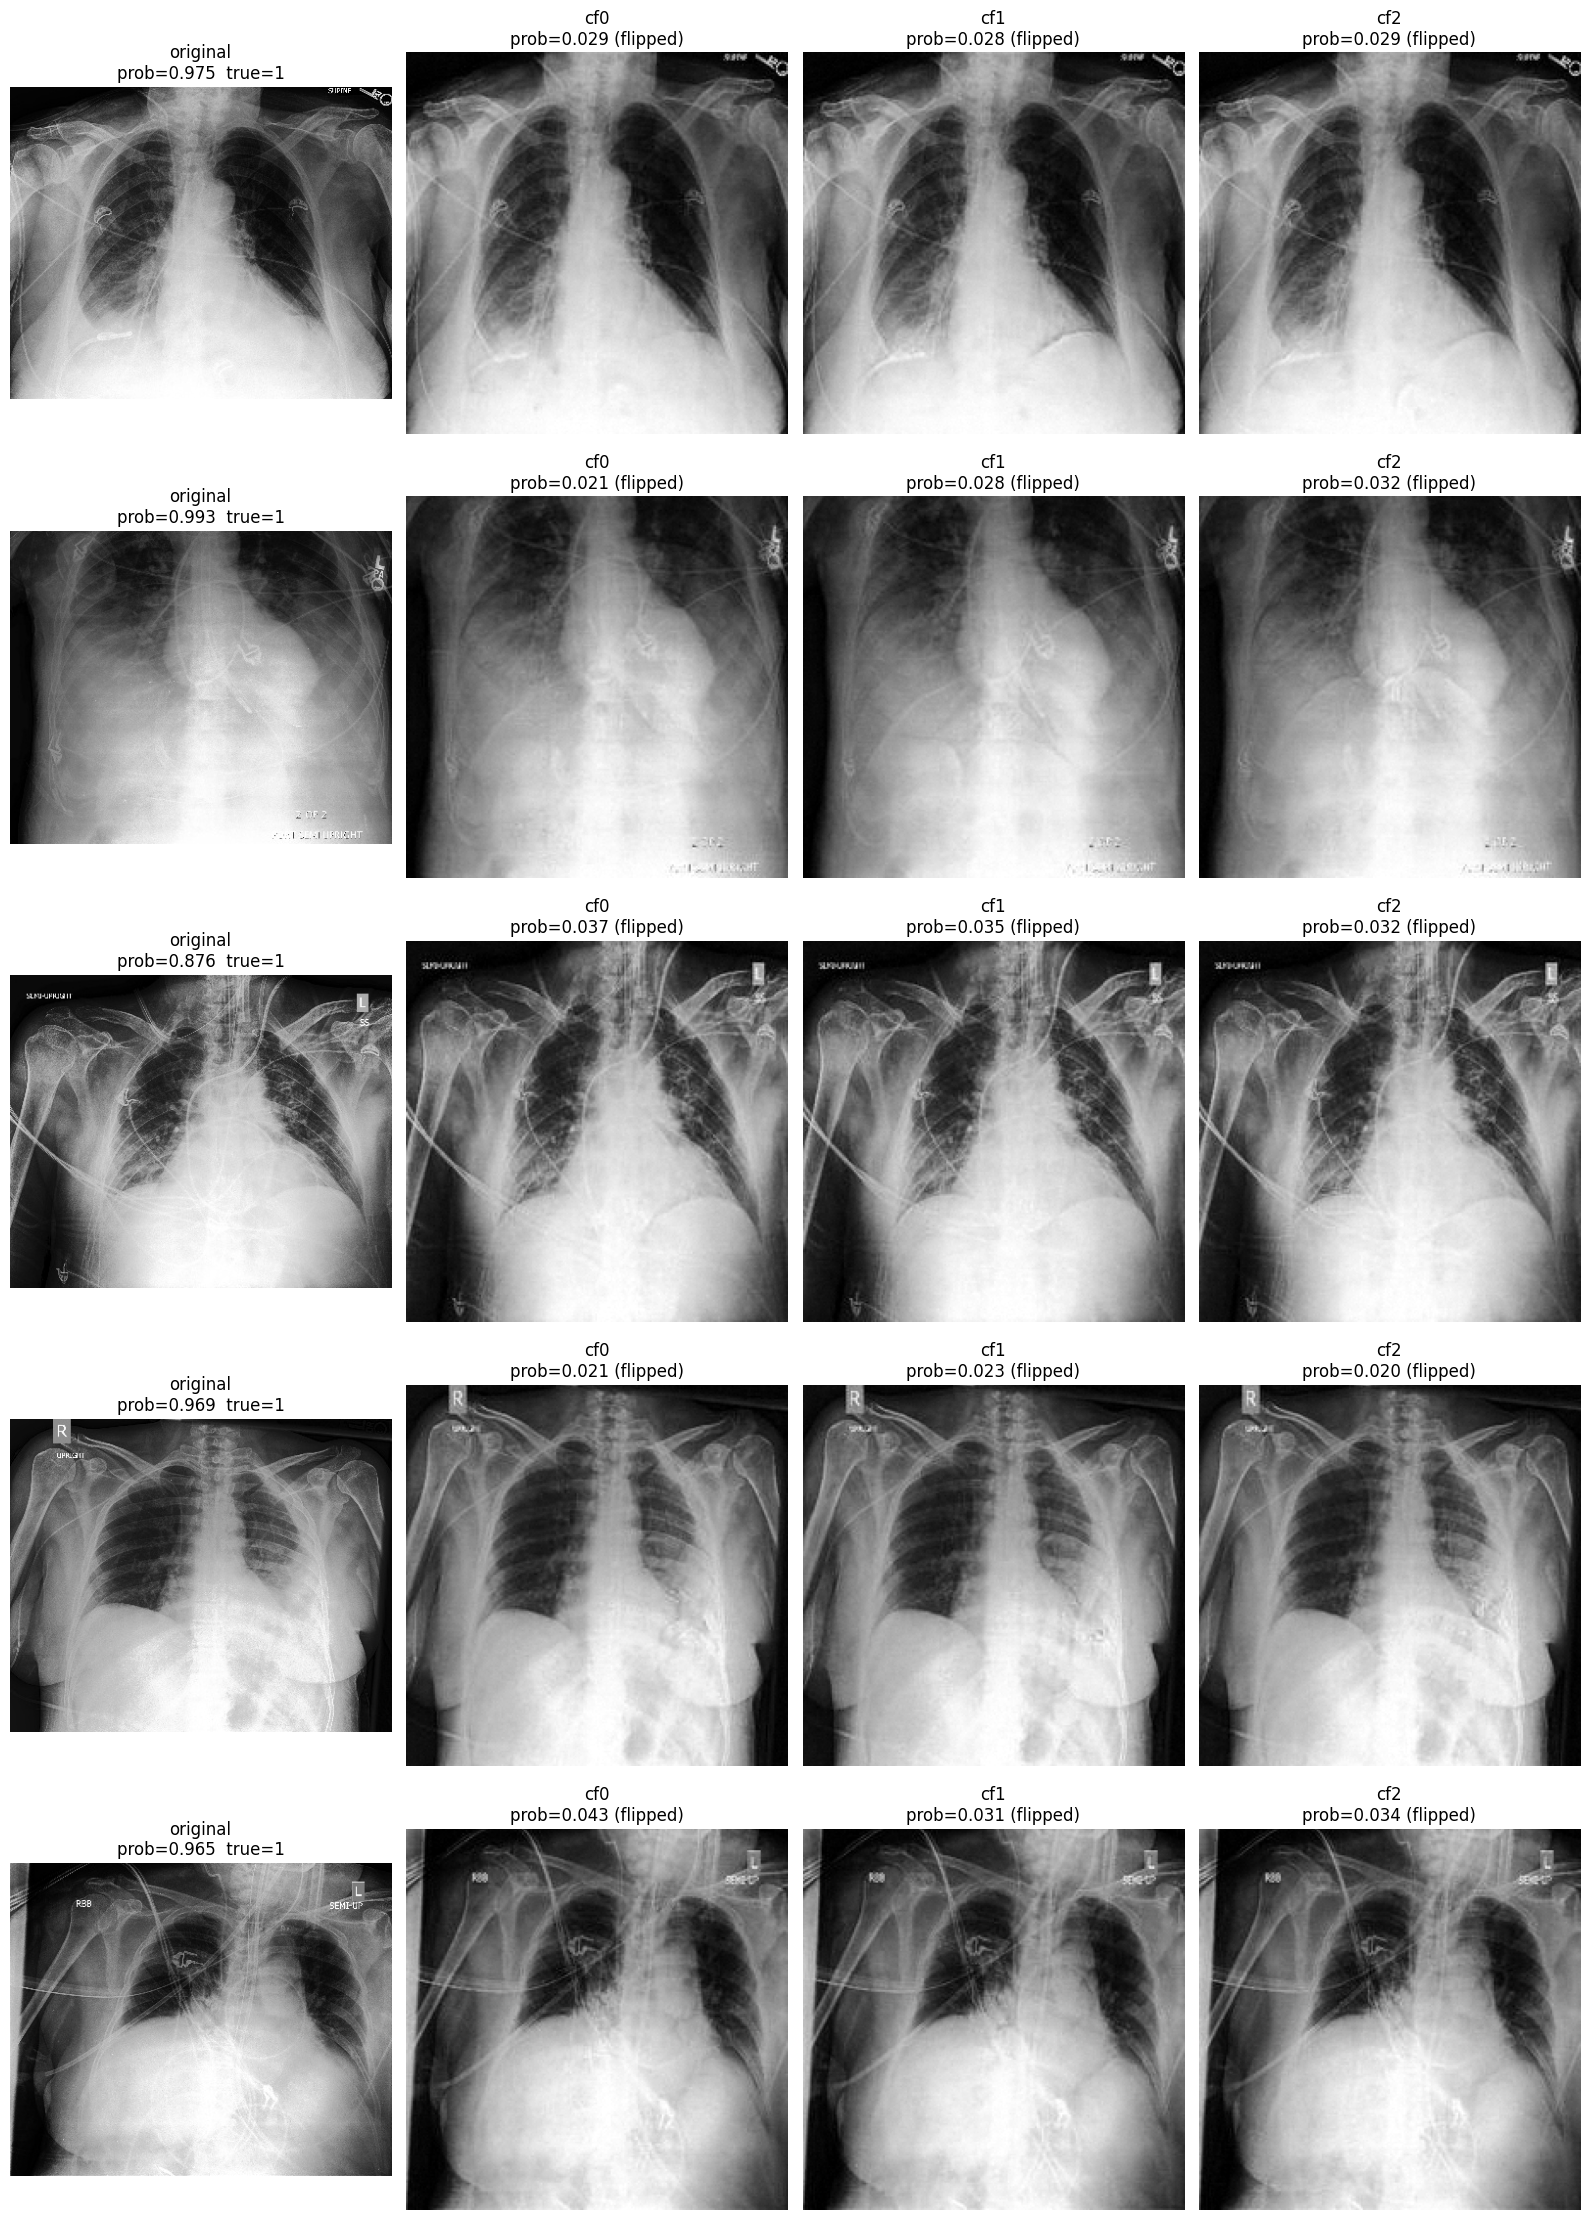

In [5]:
rng = np.random.RandomState(SEED)
sample_paths = rng.choice(manifest['path'].unique(), size=N_EXAMPLES, replace=False)

fig, axes = plt.subplots(N_EXAMPLES, 4, figsize=(16, 4.5 * N_EXAMPLES))
for row_axes, path in zip(axes, sample_paths):
    plot_triad(path, manifest, orig, ax_row=row_axes)

plt.tight_layout()
plt.show()

## Pick a specific image
Useful once you've spotted an interesting `path` from the diversity diagnosis (e.g. one with a large `cf_prob` range across seeds).

In [6]:
# path = "CheXpert-v1.0-small/train/patient18234/study4/view1_frontal.jpg"
# plot_triad(path, manifest, orig)
# plt.tight_layout()
# plt.show()